In [1]:
import pandas as pd

df = pd.read_excel('./data/equator_pacific.xlsx')

In [2]:
df

,Age(Ma),Depth(m),Carbon_CaCO3 (wt%),Dry Density (g/cm3),SR(m/Ma),CAR(mg/cm2/kyr),Paledepth,Hole
0,0.000643,0.01,78.0,0.646779,15.551609,784.559096,3873.551399,572A
1,0.010867,19.20,0.0,0.808950,58.058054,0.000000,4158.102362,495
2,0.011256,0.30,5.1,0.223000,26.745610,30.417782,3709.811273,845A
3,0.015872,0.33,73.6,0.500000,20.862285,767.732078,3786.575383,850A
4,0.018605,1.50,2.3,1.128233,80.913455,209.965290,5934.445039,499
...,...,...,...,...,...,...,...,...
5006,81.721702,402.16,74.5,0.655248,2.075855,101.334878,5303.843803,199
5007,81.973687,120.25,67.7,0.947108,2.725044,174.727745,4541.536703,170
5008,82.528244,120.59,1.1,0.949959,2.993129,3.127685,4531.920214,170
5009,99.977017,185.23,7.4,0.951720,1.056000,7.437121,4180.559000,170


In [3]:
age = df['Age(Ma)']
CAR = df['CAR(mg/cm2/kyr)']

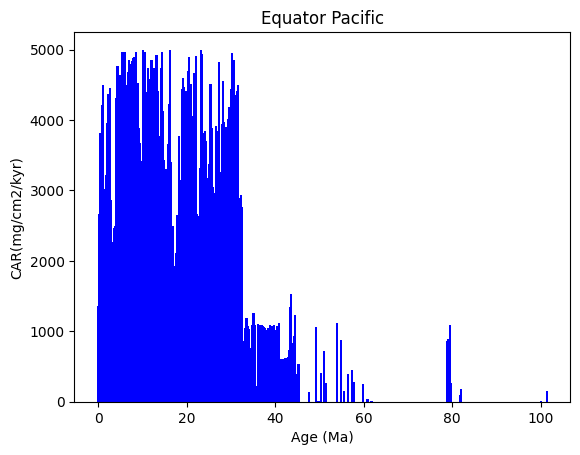

In [4]:
import matplotlib.pyplot as plt

plt.bar(age, CAR, width=0.5, color='blue', label='CAR(mg/cm2/kyr)')

# # 设置x轴范围
# plt.xlim(0, 100)  
# # 设置y轴范围
# plt.ylim(0, 70)

plt.xlabel('Age (Ma)')
plt.ylabel('CAR(mg/cm2/kyr)')
plt.title('Equator Pacific')

plt.show()

In [5]:
import numpy as np

# 30%加权移动平均
car_30_per_wa_trend = CAR.rolling(window=3, min_periods=1, center=True).apply(lambda x: np.dot(x, np.array([[0.3], [0.35], [0.35]])[:len(x)]))

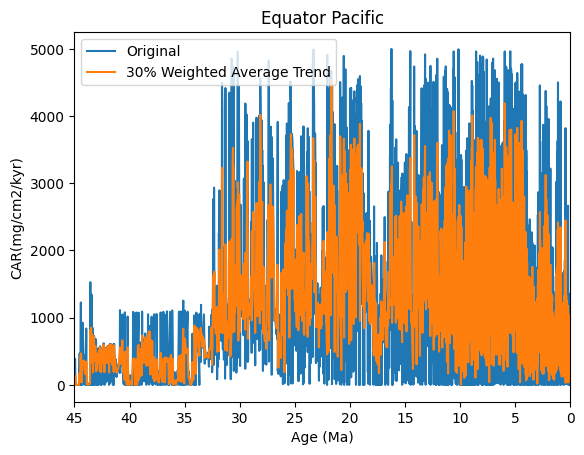

In [6]:
plt.plot(age, CAR, label='Original')
plt.plot(age, car_30_per_wa_trend, label='30% Weighted Average Trend') 

# 设置x轴范围
plt.xlim(45, 0)

plt.xlabel('Age (Ma)')
plt.ylabel('CAR(mg/cm2/kyr)')
plt.title('Equator Pacific')
plt.legend()

plt.show()

In [8]:
car_30_per_wa_detrended = CAR - car_30_per_wa_trend

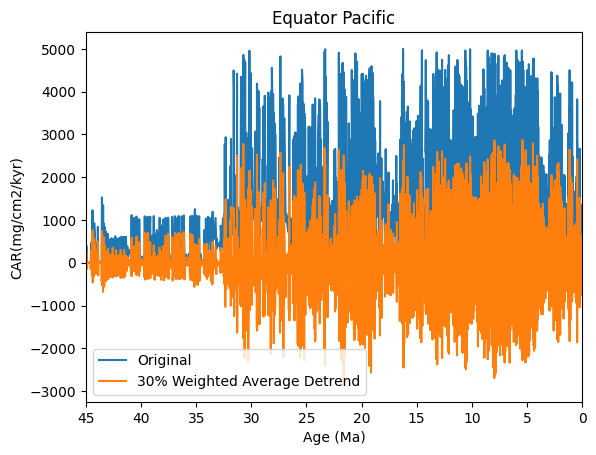

In [9]:
plt.plot(age, CAR, label='Original')
plt.plot(age, car_30_per_wa_detrended, label='30% Weighted Average Detrend') 

# 设置x轴范围
plt.xlim(45, 0)

plt.xlabel('Age (Ma)')
plt.ylabel('CAR(mg/cm2/kyr)')
plt.title('Equator Pacific')
plt.legend()

plt.show()

In [10]:
series = np.array(car_30_per_wa_detrended)
series = series - np.mean(series)   # 中心化(非必须)

In [11]:
N = len(series)

# 用于创建轨迹矩阵
def trajectory_matrix(X, k):
    N = len(X)
    L = N - k + 1
    out = []
    for i in range(L):
        out.append(X[i:k+i])
    out = np.asarray(out)
    return out

In [12]:
# 创建轨迹矩阵
# N=25, K=4, L=N-K+1
K = 4
L = N - K + 1
print(f"L={L}, K={K}")
X = trajectory_matrix(series, K)
print(X.shape)

L=5008, K=4
(5008, 4)


In [13]:
# 奇异值分解，注意以下numpy实现的svd已经对奇异值降序排序了，对应奇异向量也已经重新排序了。
U, s, VT = np.linalg.svd(X)

In [14]:
# rank of X
r = np.linalg.matrix_rank(X)
print(f"rank={r}")

rank=4


In [15]:
# 分组，这里默认每个奇异值作为一个组，所以从0遍历到r-1，共r个分组。
Xs = [] 
for i in range(r):
    t = s[i] * U[:, i][:,None] @ VT[i,:][:,None].T
    Xs.append(t)
print(len(Xs))
X1 = Xs[0]
X2 = Xs[1] 
X3 = Xs[2]
X4 = Xs[3]

4


In [16]:
# 用于计算矩阵反对角线的均值
def average_anti_diag(X):
    """
    Average antidiagonal elements of a 2D matrix.
    
    Parameters:
    ----------------------------------
    X: np.array
       2D numpy array of size
    Return:
    ---------------------------------
    out: 1D array
        1D array representing averaged antidiagonal elements of X
    """
    X = np.asarray(X)
    out = [np.mean(X[::-1, :].diagonal(i)) for i in range(-X.shape[0]+1, X.shape[1])]
    
    return np.asarray(out)

In [17]:
# 计算各个分组的子矩阵的反对角线的均值，并得到一个子序列
RC1 = average_anti_diag(X1)
RC2 = average_anti_diag(X2)
RC3 = average_anti_diag(X3)
RC4 = average_anti_diag(X4)

In [18]:
# 将得到的子序列求和得到重构的时间序列, 注意：PNAS的原文只用了RC2和RC3重建，相当于完成了滤波
Y_reconstructed = RC1

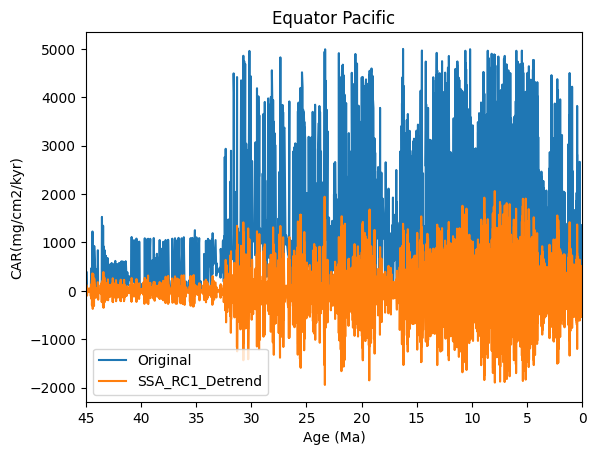

In [19]:
plt.plot(age, CAR, label='Original')
plt.plot(age, Y_reconstructed, label='SSA_RC1_Detrend')

# 设置x轴范围
plt.xlim(45, 0)

plt.xlabel('Age (Ma)')
plt.ylabel('CAR(mg/cm2/kyr)')
plt.title('Equator Pacific')
plt.legend()

plt.show()

In [20]:
from scipy.ndimage import gaussian_filter1d

# 高斯滤波
filtered = gaussian_filter1d(series, sigma=0.01)

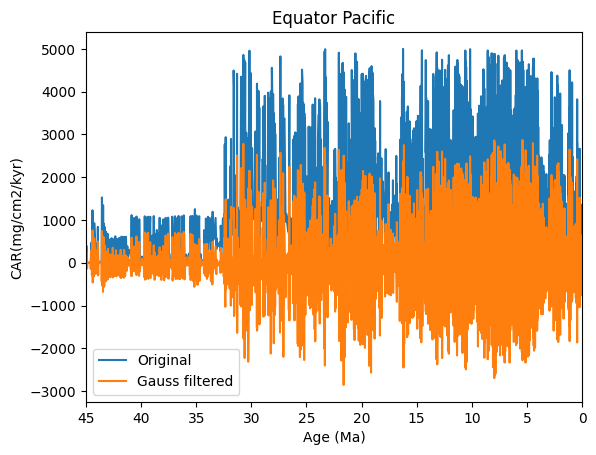

In [21]:
plt.plot(age, CAR, label='Original')
plt.plot(age, filtered, label='Gauss filtered')

# 设置x轴范围
plt.xlim(45, 0)

plt.xlabel('Age (Ma)')
plt.ylabel('CAR(mg/cm2/kyr)')
plt.title('Equator Pacific')
plt.legend()

plt.show()

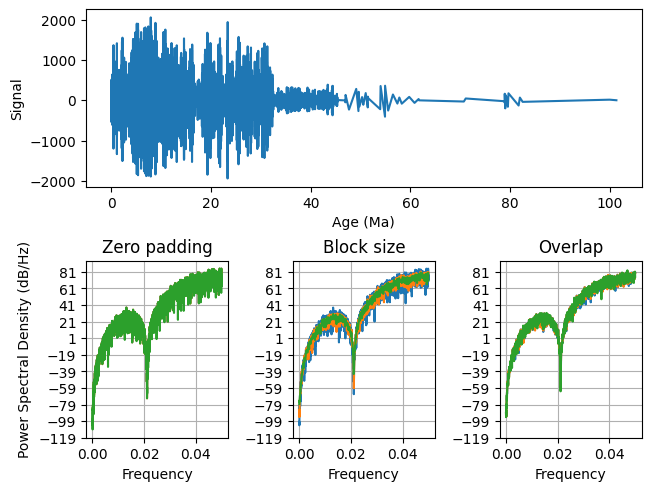

In [22]:
import matplotlib.gridspec as gridspec

"""
在不同分辨率下PSD分解
"""

# Plot the raw time series
fig = plt.figure(constrained_layout=True)
gs = gridspec.GridSpec(2, 3, figure=fig)
ax = fig.add_subplot(gs[0, :])
ax.plot(age, Y_reconstructed, label='SSA_RC1_Detrend')
ax.set_xlabel('Age (Ma)')
ax.set_ylabel('Signal')

# Plot the PSD with different amounts of zero padding. This uses the entire
# time series at once
ax2 = fig.add_subplot(gs[1, 0])
ax2.psd(Y_reconstructed, NFFT=len(Y_reconstructed), pad_to=len(Y_reconstructed), Fs=0.1)
ax2.psd(Y_reconstructed, NFFT=len(Y_reconstructed), pad_to=len(Y_reconstructed) * 2, Fs=0.1)
ax2.psd(Y_reconstructed, NFFT=len(Y_reconstructed), pad_to=len(Y_reconstructed) * 4, Fs=0.1)
plt.title('Zero padding')

# Plot the PSD with different block sizes, Zero pad to the length of the
# original data sequence.
ax3 = fig.add_subplot(gs[1, 1], sharex=ax2, sharey=ax2)
ax3.psd(Y_reconstructed, NFFT=len(Y_reconstructed), pad_to=len(Y_reconstructed), Fs=0.1)
ax3.psd(Y_reconstructed, NFFT=len(Y_reconstructed) // 2, pad_to=len(Y_reconstructed), Fs=0.1)
ax3.psd(Y_reconstructed, NFFT=len(Y_reconstructed) // 4, pad_to=len(Y_reconstructed), Fs=0.1)
ax3.set_ylabel('')
plt.title('Block size')

# Plot the PSD with different amounts of overlap between blocks
ax4 = fig.add_subplot(gs[1, 2], sharex=ax2, sharey=ax2)
ax4.psd(Y_reconstructed, NFFT=len(Y_reconstructed) // 2, pad_to=len(Y_reconstructed), noverlap=0, Fs=0.1)
ax4.psd(Y_reconstructed, NFFT=len(Y_reconstructed) // 2, pad_to=len(Y_reconstructed),
        noverlap=int(0.05 * len(Y_reconstructed) / 2.), Fs=0.1)
ax4.psd(Y_reconstructed, NFFT=len(Y_reconstructed) // 2, pad_to=len(Y_reconstructed),
        noverlap=int(0.2 * len(Y_reconstructed) / 2.), Fs=0.1)
ax4.set_ylabel('')
plt.title('Overlap')

plt.show()

In [23]:
import numpy as np
from numpy import fft
from numpy.fft import ifft
from scipy.special import gamma
from scipy.stats.distributions import chi2
import matplotlib.pyplot as plt

def wave_bases(mother,k,scale,param):
    n = k.shape[0]
    k_tmp = k.copy()
    k_tmp[k_tmp>0]=1
    k_tmp[k_tmp<=0]=0
    if (mother =='MORLET'):
        k0 = param
        expnt = (-1)*(scale*k - k0)**2/2*k_tmp
        norm = np.sqrt(scale*k[1])*(np.pi**(-0.25))*np.sqrt(n)
        daughter = norm*np.exp(expnt)
        daughter = daughter*k_tmp     
        fourier_factor = (4*np.pi)/(k0 + np.sqrt(2 + k0**2))
        coi = fourier_factor/np.sqrt(2)
        dofmin = 2
    elif (mother =='PAUL'):
        m = param
        expnt = (-1)*(scale*k)*k_tmp
        norm = np.sqrt(scale*k[1])*(2**m/np.sqrt(m*np.prod(np.arange(2,2*m))))*np.sqrt(n)
        daughter = norm*((scale*k)**m)*np.exp(expnt)
        daughter = daughter*k_tmp  
        fourier_factor = 4*np.pi/(2*m+1)
        coi = fourier_factor*np.sqrt(2)
        dofmin = 2
    elif (mother =='DOG'):
        m = param
        expnt = (-1)*(scale*k)**2/2.0
        norm = np.sqrt(scale*k[1]/gamma(m+0.5))*np.sqrt(n)
        daughter = (-1)*norm*((1j)**m)*((scale*k)**m)*np.exp(expnt)
        fourier_factor = 2*np.pi*np.sqrt(2/(2*m+1))
        coi = fourier_factor/np.sqrt(2)
        dofmin = 1
    return daughter,fourier_factor,coi,dofmin
 
def wavelet(Y,dt,pad,dj,s0,J1,mother,param):
    n1 = Y.shape[0]
    x = (Y - Y.mean())
    if (pad == 1):
        base2 = np.trunc(np.log(n1)/np.log(2) + 0.4999).astype('int32')
        x = np.hstack((x,np.zeros((2**(base2+1)-n1))))
    n = x.shape[0]
    k = np.arange(1,n//2+1,1)
    k = k*((2*np.pi)/(n*dt))
    k = np.hstack((0,k,((-1)*k[np.arange((n-1)//2-1,-1,-1)])))
    f = np.fft.fft(x)
    scale = s0*2**(np.arange(0,J1+1)*dj)
    period = scale
    wave = np.zeros((np.array(J1+1).astype('int32'),n))
    wave = wave + (1j)*wave
    for i in range(1,np.array(J1+2).astype('int32')):
        daughter,fourier_factor,coi,dofmin = wave_bases(mother,k,scale[i-1],param)
        wave[i-1,:] = ifft(f*daughter)
    period = fourier_factor*scale
    coi = coi*dt*np.hstack((1e-5,np.arange(1,(n1+1)//2,1),np.arange(1,n1//2,1)[::-1],1e-5))
    wave = wave[:,:n1]
    return wave,period,scale,coi

def wave_signif(Y,dt,scale1,sigtest,lag1,siglvl,dof,mother,param):
    n1 = np.array([Y]).shape
    J1 = scale1.shape[0] - 1
    scale[:J1+1] = scale1
    s0 = np.min(scale)
    dj = np.log(scale[1]/scale[0])/np.log(2)
    variance = Y
    if (mother =='MORLET'):
        k0 = param
        fourier_factor = (4*np.pi)/(k0 + np.sqrt(2 + k0**2))
        empir = np.array([2.,-1,-1,-1])
        if (k0==6):
            empir[1:]= np.array([0.776,2.32,0.60])
    elif (mother =='PAUL'):
        m = param
        fourier_factor = 4*np.pi/(2*m+1)
        empir = np.array([2.,-1,-1,-1])
        if (m==4):
            empir[1:]= np.array([1.132,1.17,1.5])
    elif (mother =='DOG'):
        m = param
        fourier_factor = 2*np.pi*np.sqrt(2/(2*m+1))
        empir = np.array([1,-1,-1,-1])
        if (m==2):
            empir[1:]= np.array([3.541,1.43,1.4])
        elif (m==6):
            empir[1:]= np.array([1.966,1.37,0.97])
    period = scale*fourier_factor
    dofmin = empir[0]
    Cdelta = empir[1]
    gamma_fac = empir[2]
    dj0 = empir[3]
    freq = dt / period
    fft_theor = (1-lag1**2) / (1-2*lag1*np.cos(freq*2*np.pi)+lag1**2)
    fft_theor = variance*fft_theor
    signif = fft_theor
    if (np.array(dof).sum() == -1):
        dof = dofmin
    if (sigtest == 0):
        dof = dofmin
        chisquare = chi2.ppf(siglvl,dof)/dof
        signif = fft_theor*chisquare
    elif (sigtest == 1):
        if (dof.shape[0] == 1):
            dof=np.zeros((J1+1))+dof
        dof[dof<1]=1
        dof = dofmin*np.sqrt(1 + (dof*dt/gamma_fac/ scale)**2 )
        dof[dof<dofmin]=dofmin
        for i in np.arange(1,J1+2):
            chisquare = chi2.ppf(siglvl,dof[i-1])/dof[i-1]
            signif[i-1] = fft_theor[i-1]*chisquare
    elif (sigtest == 2):
        s1 = dof[0]
        s2 = dof[1]
        avg = np.array(np.where((scale >= s1)&(scale < s2))).reshape(-1)
        navg = avg.shape[0]
        Savg = 1/np.sum(1/ scale[avg],axis=(0))
        Smid = np.exp((np.log(s1)+np.log(s2))/2.)
        dof = (dofmin*navg*Savg/Smid)*np.sqrt(1 + (navg*dj/dj0)**2)
        fft_theor = Savg*np.sum(fft_theor[avg]/ scale[avg])
        chisquare = chi2.ppf(siglvl,dof)/dof
        signif = (dj*dt/Cdelta/Savg)*fft_theor*chisquare    
    return signif,fft_theor

In [36]:
#参数设置
n = len(Y_reconstructed)
dt = 0.25
time = age
pad = 1;     # 边缘效应
dj = 0.25  # 
s0 = 2*dt    # 最小尺度从逐1个Ma开始
j1 = 10/dj    # 
lag1 = 0.7 # 
mother = 'MORLET'

In [37]:
#计算小波
variance = Y_reconstructed.std()*Y_reconstructed.std()
STD_Y_reconstructed = ((Y_reconstructed - Y_reconstructed.mean())/Y_reconstructed.std())
wave,period,scale,coi = wavelet(STD_Y_reconstructed,dt,pad,dj,s0,j1,mother,6)
power = (np.abs(wave))**2
#显著性检验
signif,fft_theor = wave_signif(1,dt,scale,0,lag1,0.95,0,mother,6)
sig95 = (signif.T).reshape((-1,1))*(np.zeros((n))+1).reshape((1,-1))
sig95 = power/ sig95

global_ws = variance*(np.sum(power.T,axis = 0)/n)
dof = n - scale
global_signif,_ = wave_signif(variance,dt,scale,1,lag1,0.95,dof,mother,6)
avg = np.where((scale >= 2)&(scale < 8))
Cdelta = 0.776
scale_avg = (scale.T).reshape((-1,1))*(np.zeros((n))+1).reshape((1,-1))
scale_avg = power/ scale_avg
scale_avg = variance*dj*dt/Cdelta*np.sum(scale_avg[avg,:],axis = (0,1))
scaleavg_signif,_ = wave_signif(variance,dt,scale,2,lag1,0.95,np.array([2,7.9]),mother,6)

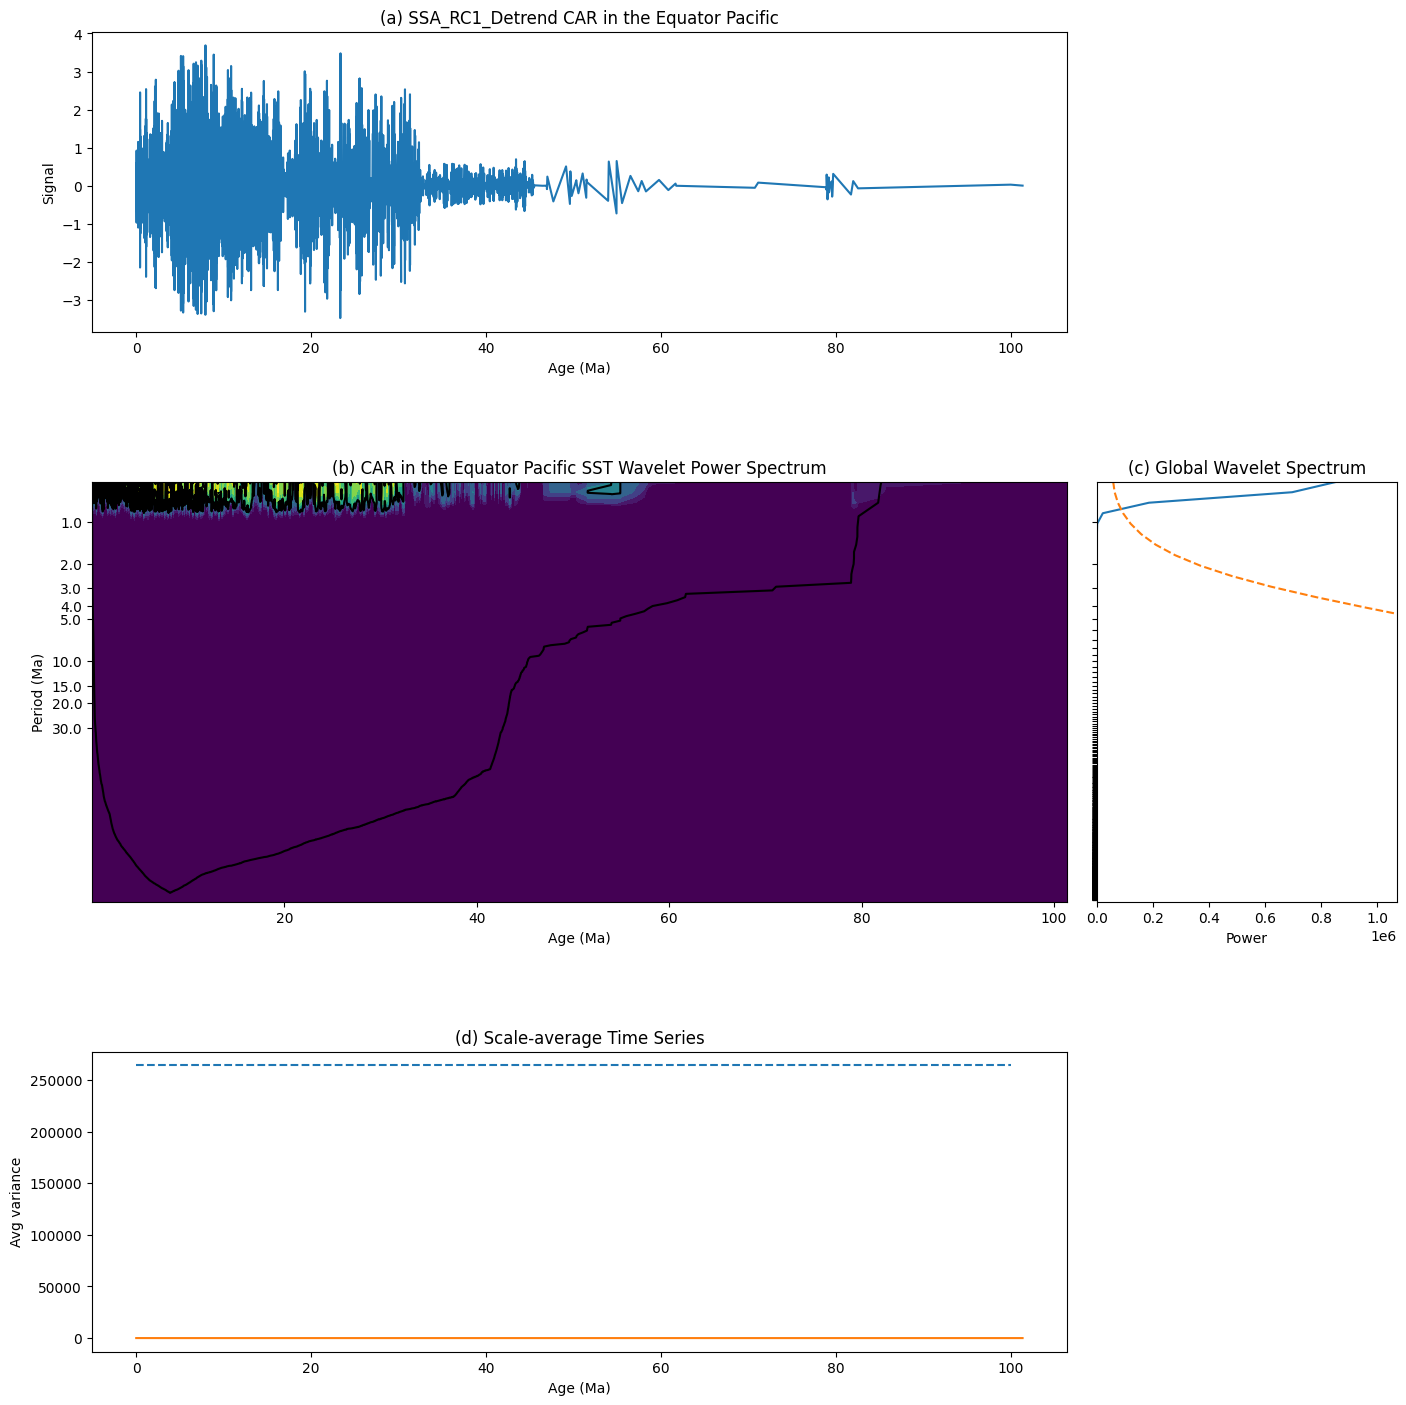

In [38]:
#原始数据序列
xlim = np.array([0,100])
fig = plt.figure(figsize=(15,15))
f_ax1 = fig.add_axes([0.1,0.75,0.65,0.2])
f_ax1.plot(age,STD_Y_reconstructed)
f_ax1.set_xlabel('Age (Ma)')
f_ax1.set_ylabel('Signal')
f_ax1.set_title('(a) SSA_RC1_Detrend CAR in the Equator Pacific')
#小波
f_ax2 = fig.add_axes([0.1, 0.37 ,0.65 ,0.28])
levels = [0.0625,0.125,0.25,0.5,1,2,4,8,16]
Yticks = np.arange(2**np.trunc(np.log2(np.min(period))),2**np.trunc(np.log2(np.max(period)))+1,1)
f_ax2.contourf(time,np.log2(period),np.log2(power),np.log2(levels),extend='both')
f_ax2.set_xlabel('Age (Ma)')
f_ax2.set_ylabel('Period (Ma)')
f_ax2.set_title('(b) CAR in the Equator Pacific SST Wavelet Power Spectrum')
f_ax2.set_ylim(np.log2(np.max(period)),np.log2(np.min(period)))
f_ax2.contour(time,np.log2(period),sig95,levels=[-99,1],colors ='k')
f_ax2.plot(time,np.log2(coi),'k')
f_ax2.set_yticks(np.log2(Yticks)[[0,1,2,3,4,9,14,19,29]])
f_ax2.set_yticklabels(Yticks[[0,1,2,3,4,9,14,19,29]])
#全局功率谱
f_ax3 = fig.add_axes([0.77, 0.37, 0.2, 0.28])
f_ax3.plot(global_ws,np.log2(period))
f_ax3.plot(global_signif,np.log2(period),'--')
f_ax3.set_xlabel('Power')
f_ax3.set_title('(c) Global Wavelet Spectrum')
f_ax3.set_ylim(np.log2([np.max(period),np.min(period)]))
f_ax3.set_yticks(np.log2(Yticks))
f_ax3.set_yticklabels('')
f_ax3.set_xlim(0,1.25*np.max(global_ws))
#局部功率谱
f_ax4 = fig.add_axes([0.1,0.07 ,0.65, 0.2])
f_ax4.plot(xlim,scaleavg_signif+np.array([0,0]),'--')
f_ax4.plot(time,scale_avg)
f_ax4.set_xlabel('Age (Ma)')
f_ax4.set_ylabel('Avg variance')
f_ax4.set_title('(d) Scale-average Time Series')

plt.show()

In [31]:
import scipy.signal as signal

# 脱趋
detrended = signal.detrend(series)

# 2pi-MTM幅值谱
freq, psd = signal.welch(detrended, nperseg=2048)

# Find indices of top 3 psd values
top3_idx = np.argsort(psd)[-3:]

# Get corresponding freqs
top3_freqs = freq[top3_idx]

# Compute periods and ages
top3_periods = 1 / top3_freqs
top3_ages = top3_periods / (1/12) 

print("Top 3 dominant periods:")
print(top3_periods) 

print("Corresponding ages:")
print(top3_ages, "Ma")

Top 3 dominant periods:
[2.03174603 2.12889813 2.16033755]
Corresponding ages:
[24.38095238 25.54677755 25.92405063] Ma


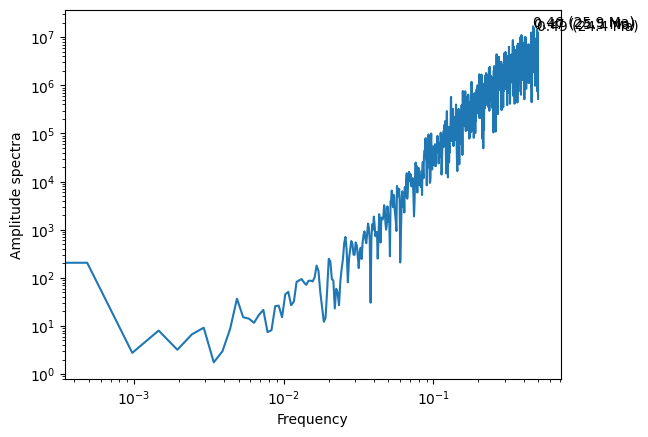

In [32]:
# 绘制振幅谱,双对数坐标
plt.loglog(freq, psd)

# 获取top3 psd值对应的索引
top3_psd_idx = np.argsort(psd)[-3:]

# plt.xlim([1e-3, 1])
# plt.ylim([1e-1, 1e2])

for i in range(3):
    psd_val = psd[top3_psd_idx[i]]
    plt.annotate(f"{top3_freqs[i]:.2f} ({top3_ages[i]:.1f} Ma)",
                xy=(top3_freqs[i], psd_val)) 

plt.xlabel('Frequency')
plt.ylabel('Amplitude spectra')
plt.show()